In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../wildfire-dataset")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 03. Weather (ERA5-Land)

**What is it?** A reanalysis: a computer model of the weather fitted to measurements, on a 0.1 degree grid, one value per day.
We downloaded it through Google Earth Engine as daily CSV tables.

**Why?** Fires depend on dryness. Hot, dry, windy days after a dry spell are the dangerous ones.

We have the weather in two batches with **exactly the same format**: the first six states (Chhattisgarh, Jharkhand, Maharashtra, Madhya Pradesh, Odisha, Telangana)
and the newer states (south, Himachal, north-east, blind). Both are shown together below. All 84 months of the first six states are in our cloud bucket; we copied January to March 2022 to `inputs_raw/gee_six_states/`.

Andhra Pradesh and Uttarakhand (sets D1 and D2, 828 cells) were built earlier from a separate export; their raw files are not part of what is shown here.

## 1. Raw file

In [2]:
SOURCES = {"newer states": RAW + "/gee_new_states", "first six states": RAW + "/gee_six_states"}
print("monthly files on disk: newer states", len(glob.glob(SOURCES["newer states"] + "/era5land_daily/*.csv")), "(2019-01 to 2025-12);  first six states", len(glob.glob(SOURCES["first six states"] + "/era5land_daily/*.csv")), "(copied sample, 2022-01 to 2022-03)")
era = pd.concat(pd.read_csv(p + "/era5land_daily/era5_2022_03.csv").assign(source=k) for k, p in SOURCES.items())
print("March 2022, both batches together:", len(era), "rows =", era.cell_id.nunique(), "cells x", era.date.nunique(), "days")
era.groupby("source").cell_id.nunique().to_frame("cells in the raw files")
era.head(4)

monthly files on disk: newer states 84 (2019-01 to 2025-12);  first six states 3 (copied sample, 2022-01 to 2022-03)
March 2022, both batches together: 570121 rows = 18391 cells x 31 days


,cell_id,lon,lat,date,temperature_2m,temperature_2m_max,temperature_2m_min,dewpoint_temperature_2m,u_component_of_wind_10m,v_component_of_wind_10m,total_precipitation_sum,volumetric_soil_water_layer_1,source
0,81775,77.5,8.1,2022-03-01,301.149229,305.450424,297.603088,292.106771,-3.315601,-2.885768,1.490116e-08,0.060727,newer states
1,82773,77.3,8.2,2022-03-01,300.874327,306.472641,294.679123,290.353272,-0.714689,-0.358587,6.854534e-07,0.090227,newer states
2,82774,77.4,8.2,2022-03-01,300.954974,306.908188,295.439026,290.119385,-1.651823,-1.164007,0.000000e+00,0.087264,newer states
3,82775,77.5,8.2,2022-03-01,301.174131,306.601547,296.634338,290.853679,-2.423185,-2.191757,0.000000e+00,0.087542,newer states


One row = one cell and one day. All temperatures are in **kelvin** (0 C = 273.15 K). Rain is in **metres** per day.

| raw column | meaning |
|---|---|
| `temperature_2m` | average air temperature 2 m above ground |
| `temperature_2m_max`, `_min` | hottest and coolest value of the day |
| `dewpoint_temperature_2m` | how humid the air is (the temperature at which dew forms) |
| `u_component_of_wind_10m`, `v_component_of_wind_10m` | wind east-west and north-south, 10 m up, in m/s |
| `total_precipitation_sum` | rain of the day, metres |
| `volumetric_soil_water_layer_1` | water in the top 7 cm of soil (fraction of volume) |

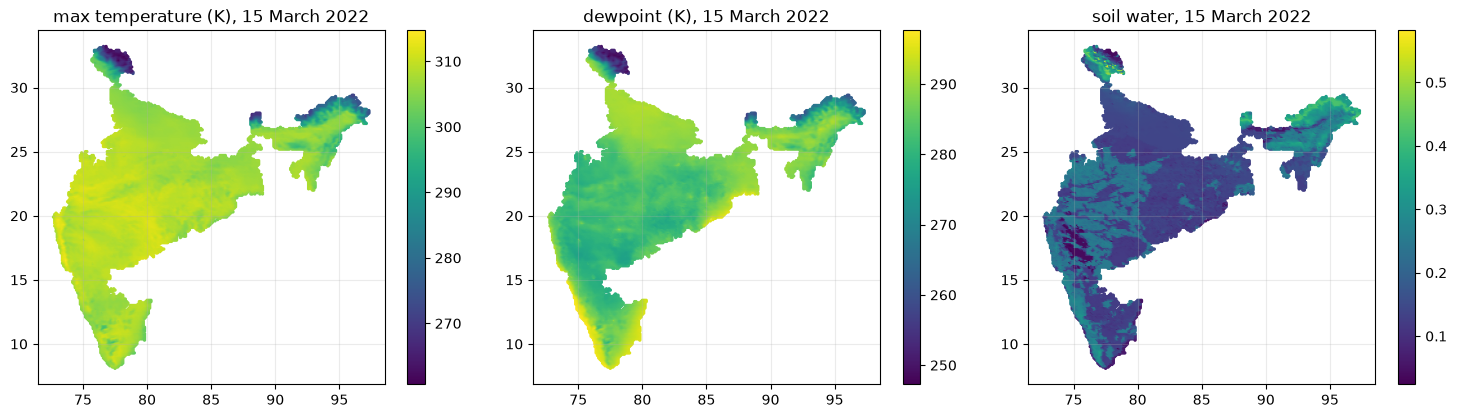

empty rows in this month: 1674 = 54 cells that have no ERA5-Land value on any day (sea / coast, the land model has no data there)


In [3]:
day = era[era.date == "2022-03-15"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, ttl in zip(ax, ["temperature_2m_max", "dewpoint_temperature_2m", "volumetric_soil_water_layer_1"], ["max temperature (K)", "dewpoint (K)", "soil water"]):
    sc = a.scatter(day.lon, day.lat, c=day[col], s=2, cmap="viridis"); plt.colorbar(sc, ax=a); a.set_title(ttl + ", 15 March 2022"); a.set_aspect("equal")
plt.tight_layout(); plt.show()
nanrows = era.temperature_2m.isna().sum()
print("empty rows in this month:", nanrows, "=", nanrows // era.date.nunique(), "cells that have no ERA5-Land value on any day (sea / coast, the land model has no data there)")

## 2. The raw numbers are not what the model reads

first six states -> chosen cell: 157741 MH lat 15.7 lon 74.1
newer states -> chosen cell: 83774 Tamil Nadu lat 8.3 lon 77.4


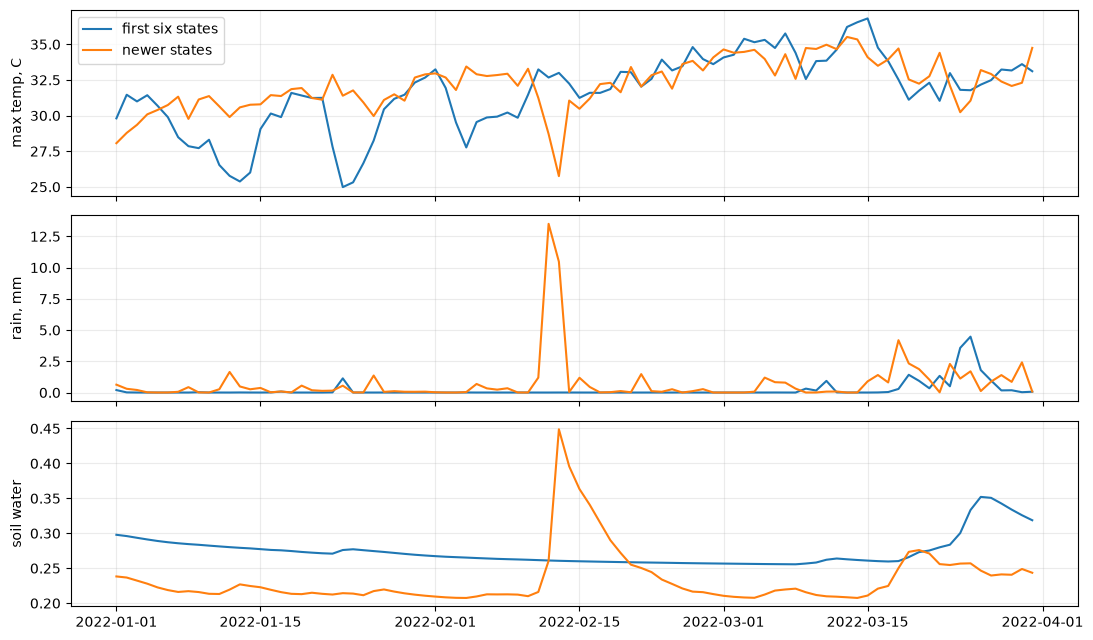

In [4]:
# two cells, one from each batch, three months of raw values
the = pd.concat(pd.read_csv(p + f"/era5land_daily/era5_2022_{m:02d}.csv") for p in SOURCES.values() for m in (1, 2, 3))
cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
picked = {}
for label, group in [("first six states", "six"), ("newer states", "south")]:
    picked[label] = cells[(cells.set == group) & cells.cell_id.isin(the.cell_id.unique())].iloc[0]
    print(label, "-> chosen cell:", int(picked[label].cell_id), picked[label].state, "lat", picked[label].lat, "lon", picked[label].lon)
raw_cells = {}
for label, r in picked.items():
    c = the[the.cell_id == r.cell_id].sort_values("date").reset_index(drop=True); c["date"] = pd.to_datetime(c.date); raw_cells[label] = c
fig, ax = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for label, c in raw_cells.items():
    ax[0].plot(c.date, c.temperature_2m_max - 273.15, label=label); ax[1].plot(c.date, c.total_precipitation_sum.clip(lower=0) * 1000, label=label); ax[2].plot(c.date, c.volumetric_soil_water_layer_1, label=label)
ax[0].set_ylabel("max temp, C"); ax[1].set_ylabel("rain, mm"); ax[2].set_ylabel("soil water"); ax[0].legend()
plt.tight_layout(); plt.show()

## 3. What we compute from it (the 11 weather channels)

We recompute the channels here by hand, with the same formulas as the build scripts, and compare with what is stored in the cube.

| channel | how it is made |
|---|---|
| `t2m_max`, `t2m_mean` | raw max and mean temperature, kelvin |
| `rh_min_proxy` | relative humidity at the hottest moment, estimated from max temperature and mean dewpoint |
| `vpd_max_proxy` | vapour pressure deficit (how thirsty the air is), kPa, from the same two numbers |
| `wind_speed_meanvec` | length of the (u, v) wind vector |
| `precip_day` | rain in mm (metres x 1000; negative values set to 0) |
| `precip_7d`, `precip_14d`, `precip_30d` | rain summed over the last 7, 14, 30 days including today |
| `days_since_rain` | days since the last day with at least 1 mm (capped at 30) |
| `soil_moisture` | raw soil water, top layer |

In [5]:
def es_hpa(t_c):                       # saturation vapour pressure (hPa) at temperature t_c, in Celsius
    return 6.1094 * np.exp(17.625 * t_c / (t_c + 243.04))

def weather_features(c):
    "the 11 weather channels from the raw rows of ONE cell (sorted by date)"
    e_max = es_hpa(c.temperature_2m_max - 273.15)       # at the hottest temperature of the day
    e_d   = es_hpa(c.dewpoint_temperature_2m - 273.15)  # at the dewpoint (= actual vapour pressure)
    f = pd.DataFrame({"date": c.date.values})
    f["t2m_max"] = c.temperature_2m_max.values
    f["t2m_mean"] = c.temperature_2m.values
    f["rh_min_proxy"] = np.clip(100 * e_d / e_max, 0, 100).values
    f["vpd_max_proxy"] = (np.maximum(e_max - e_d, 0) / 10).values
    f["wind_speed_meanvec"] = np.sqrt(c.u_component_of_wind_10m ** 2 + c.v_component_of_wind_10m ** 2).values
    rain = (np.maximum(c.total_precipitation_sum, 0) * 1000).reset_index(drop=True)
    f["precip_day"] = rain.values
    for w in (7, 14, 30): f[f"precip_{w}d"] = rain.rolling(w).sum().values          # includes today, needs a full window
    dsr = []; last = None
    for k, mm in enumerate(rain):
        if mm >= 1: last = k
        dsr.append(30 if last is None else min(k - last, 30))
    f["days_since_rain"] = dsr
    f["soil_moisture"] = c.volumetric_soil_water_layer_1.values
    return f

feat = {label: weather_features(c) for label, c in raw_cells.items()}
for label, f in feat.items():
    print(label); display(f.set_index("date").tail(3).round(3))

first six states


,t2m_max,t2m_mean,rh_min_proxy,vpd_max_proxy,wind_speed_meanvec,precip_day,precip_7d,precip_14d,precip_30d,days_since_rain,soil_moisture
date,,,,,,,,,,,
2022-03-29,306.313,300.540,54.406,2.312,1.326,0.183,11.662,16.027,17.462,3,0.334
2022-03-30,306.759,300.259,51.424,2.525,1.222,0.027,11.187,16.047,17.488,4,0.326
2022-03-31,306.260,299.835,51.959,2.429,1.341,0.066,7.677,16.072,17.554,5,0.319


newer states


,t2m_max,t2m_mean,rh_min_proxy,vpd_max_proxy,wind_speed_meanvec,precip_day,precip_7d,precip_14d,precip_30d,days_since_rain,soil_moisture
date,,,,,,,,,,,
2022-03-29,305.227,301.306,58.578,1.976,1.727,0.854,8.347,19.998,24.265,1,0.241
2022-03-30,305.450,300.998,58.119,2.023,1.750,2.416,8.473,21.012,26.680,0,0.249
2022-03-31,307.899,301.912,47.148,2.928,1.606,0.082,7.438,20.286,26.763,1,0.244


## 4. Do we get the same numbers as the cube?

In [6]:
import sys; sys.path.insert(0, os.path.abspath("../src"))
from wildfire_forecast import data
ds = data.load_train()
names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]

def compare_with_cube(feat, cell_idx):
    "largest difference between my numbers and the cube, for the days of March 2022"
    test = feat[feat.date >= "2022-03-01"].reset_index(drop=True)
    tt = (test.date - START).dt.days.values
    out = []
    for ch in [n for n in feat.columns if n != "date"]:
        stored = np.asarray(ds.cube[tt, cell_idx, names.index(ch)])
        out.append((ch, float(np.abs(test[ch].values - stored).max()), float(np.nanmean(stored))))
    return pd.DataFrame(out, columns=["channel", "largest difference (my numbers vs cube), 31 days", "mean value in cube"])

tables = []
for label, f in feat.items():
    t = compare_with_cube(f, int(picked[label].cell_idx)).set_index("channel")
    tables.append(t.iloc[:, 0].rename(f"largest difference, {label}"))
pd.concat(tables, axis=1)

,"largest difference, first six states","largest difference, newer states"
channel,,
t2m_max,1.525879e-05,1.525879e-05
t2m_mean,1.525879e-05,1.462301e-05
rh_min_proxy,9.129638e-05,8.723681e-05
vpd_max_proxy,7.537199e-06,7.807563e-06
wind_speed_meanvec,6.965450e-08,1.854585e-07
precip_day,2.099637e-07,2.384186e-07
precip_7d,5.092857e-07,7.477042e-07
precip_14d,6.572277e-07,1.491688e-06
precip_30d,7.883168e-07,2.084792e-06


The differences are at the level of rounding (float32), for both batches. So the cube really contains what these formulas say. Nothing hidden happens between the raw file and the cube for the weather.

## 5. What is missing or weak here

- **Relative humidity and VPD are proxies.** We have no hourly data, so we use the daily maximum temperature with the daily **mean** dewpoint. The real driest hour is somewhat drier. We named them `*_proxy` for this reason.
- **No wind gusts.** ERA5-Land gives the average wind, not the peak. Gusts spread fires.
- **ERA5-Land arrives about three months late.** It is a reanalysis, so it is not usable for a live demo or tomorrow's forecast. For the demo we need another source (Open-Meteo for the recent past, GFS for the forecast). The two sources do not give exactly the same numbers; we tested this earlier and rain was the weakest match.
- **Coarse grid.** One value per 11 km, so mountain valleys and slopes are smoothed out.
- **Day boundary.** Days are UTC days. A UTC day ends at 5:30 in the morning in India.
- **Negative rain values** exist in the raw files. We set them to 0 (the count is recorded in the build log).